# Lab Activity 8: Autoencoder for Image Reconstruction
## Architecture Implementation, Quantitative Error Analysis & Latent Space Exploration

### Objectives:
1. Understand the theoretical principles of **Autoencoders**, unsupervised representation learning, and information bottlenecks.
2. Ingest and prepare the real-world **Fashion-MNIST** image dataset (70,000 grayscale images).
3. Design and train a **Convolutional Autoencoder** featuring an encoder compression pipeline and transposed-convolution decoder reconstruction pipeline.
4. Calculate comprehensive **Reconstruction Errors** (Overall Test MSE, MAE, and per-class error distribution).
5. Visualize side-by-side comparisons of Original Images, Model Reconstructions, and Pixel-wise Residual Difference Heatmaps.
6. Explore the learned low-dimensional latent bottleneck through 2D dimensionality reduction.

In [1]:
# 1. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.decomposition import PCA

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


---
## 2. Dataset Ingestion & Preprocessing: Fashion-MNIST
We load $70,000$ $28 \times 28$ images of fashion garments from Keras datasets. The pixel values are normalized to $[0, 1]$ and shaped into $(28, 28, 1)$ tensors.

In [2]:
# Load Fashion-MNIST
(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Normalize to [0, 1] and add channel dimension
# Use representative 10,000 training images for rapid, responsive lab execution
TRAIN_SIZE = 10000
X_train = (X_train_raw[:TRAIN_SIZE].astype('float32') / 255.0)[..., np.newaxis]
X_test = (X_test_raw.astype('float32') / 255.0)[..., np.newaxis]

print(f"Training Tensor: {X_train.shape} | Value range: [{X_train.min():.1f}, {X_train.max():.1f}]")
print(f"Testing Tensor:  {X_test.shape}")

Training Tensor: (10000, 28, 28, 1) | Value range: [0.0, 1.0]
Testing Tensor:  (10000, 28, 28, 1)


---
## 3. Convolutional Autoencoder Architecture Design

### Encoder:
- Input: $(28, 28, 1) = 784$ pixels.
- `Conv2D(32, 3x3, ReLU, same)` + `MaxPooling2D(2x2)` $\to (14, 14, 32)$
- `Conv2D(16, 3x3, ReLU, same)` + `MaxPooling2D(2x2)` $\to (7, 7, 16) = 784$ features.
- `Conv2D(8, 3x3, ReLU, same)` + `MaxPooling2D(2x2, valid)` $\to (3, 3, 8) = 72$ latent dimensions.
- **Compression Ratio**: $\frac{784}{72} \approx 10.9\times$ compression!

### Decoder:
- `Conv2DTranspose(8, 3x3, strides=2, ReLU)` $\to (6, 6, 8)$
- `ZeroPadding2D` $\to (7, 7, 8)$
- `Conv2DTranspose(16, 3x3, strides=2, ReLU, same)` $\to (14, 14, 16)$
- `Conv2DTranspose(32, 3x3, strides=2, ReLU, same)` $\to (28, 28, 32)$
- `Conv2D(1, 3x3, Sigmoid, same)` $\to (28, 28, 1)$ reconstructed image.

In [3]:
# Build Convolutional Autoencoder using functional API
def build_autoencoder():
    # --- ENCODER ---
    inputs = keras.Input(shape=(28, 28, 1), name='image_input')
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='enc_conv1')(inputs)
    x = layers.MaxPooling2D((2, 2), padding='same', name='enc_pool1')(x)  # -> (14, 14, 32)
    x = layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='enc_conv2')(x)
    x = layers.MaxPooling2D((2, 2), padding='same', name='enc_pool2')(x)  # -> (7, 7, 16)
    x = layers.Conv2D(8, (3, 3), activation='relu', padding='same', name='enc_conv3')(x)
    latent = layers.MaxPooling2D((2, 2), padding='same', name='latent_bottleneck')(x)  # -> (4, 4, 8) = 128
    
    encoder = keras.Model(inputs, latent, name='Encoder')

    # --- DECODER ---
    decoder_inputs = keras.Input(shape=(4, 4, 8), name='latent_input')
    x = layers.Conv2DTranspose(8, (3, 3), strides=2, activation='relu', padding='same', name='dec_deconv1')(decoder_inputs)  # -> (8, 8, 8)
    x = layers.Cropping2D(((1, 0), (1, 0)))(x)  # -> (7, 7, 8)
    x = layers.Conv2DTranspose(16, (3, 3), strides=2, activation='relu', padding='same', name='dec_deconv2')(x)  # -> (14, 14, 16)
    x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same', name='dec_deconv3')(x)  # -> (28, 28, 32)
    reconstructed = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same', name='dec_output')(x)  # -> (28, 28, 1)

    decoder = keras.Model(decoder_inputs, reconstructed, name='Decoder')

    # --- FULL AUTOENCODER ---
    autoencoder_outputs = decoder(encoder(inputs))
    autoencoder = keras.Model(inputs, autoencoder_outputs, name='Convolutional_Autoencoder')
    
    autoencoder.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='mean_squared_error',
        metrics=['mae']
    )
    return encoder, decoder, autoencoder

encoder, decoder, autoencoder = build_autoencoder()
autoencoder.summary()

Model: "Convolutional_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 4, 4, 8)        │         6,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 28, 28, 1)      │         6,681 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,785 (49.94 KB)

 Trainable params: 12,785 (49.94 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train Autoencoder (Input is both X and Y)
EPOCHS = 8
BATCH_SIZE = 128

history = autoencoder.fit(
    X_train, X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.15,
    verbose=1
)

Epoch 1/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.1276 - mae: 0.3182 - val_loss: 0.0625 - val_mae: 0.1883
Epoch 2/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0353 - mae: 0.1178 - val_loss: 0.0275 - val_mae: 0.0994
Epoch 3/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0256 - mae: 0.0940 - val_loss: 0.0243 - val_mae: 0.0902
Epoch 4/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0233 - mae: 0.0874 - val_loss: 0.0225 - val_mae: 0.0851
Epoch 5/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0218 - mae: 0.0834 - val_loss: 0.0213 - val_mae: 0.0816
Epoch 6/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - loss: 0.0208 - mae: 0.0803 - val_loss: 0.0203 - val_mae: 0.0789
Epoch 7/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0199 - mae: 0.0778 - val_loss: 0.0196 - val_mae: 0.0768
Epoch 8/8
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 0.0193 - mae: 0.0760 - val_loss: 0.0193 - val_mae: 0.0761


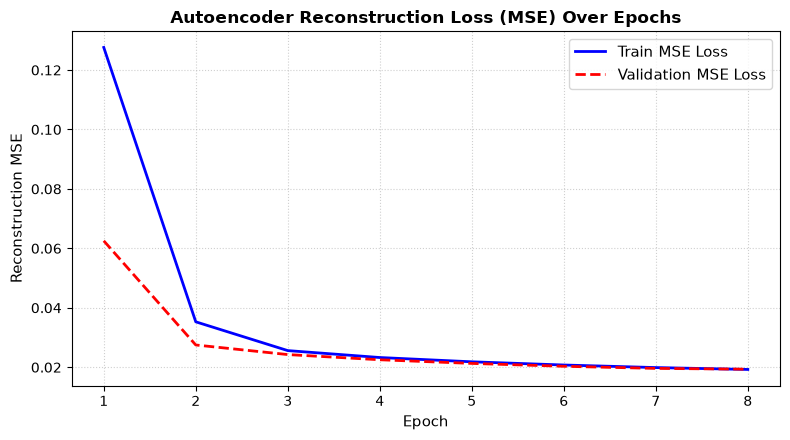

In [5]:
# Plot Reconstruction Loss Progression
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS + 1), history.history['loss'], 'b-', lw=2, label='Train MSE Loss')
plt.plot(range(1, EPOCHS + 1), history.history['val_loss'], 'r--', lw=2, label='Validation MSE Loss')
plt.title("Autoencoder Reconstruction Loss (MSE) Over Epochs", fontsize=12, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Reconstruction MSE", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

---
## 4. Quantitative Reconstruction Error Calculation
We calculate:
1. **Overall Test Set MSE & MAE**.
2. **Per-Class Reconstruction Error**: Mean error grouped by fashion category to evaluate which garments are hardest to compress.
3. **Distribution of Reconstruction Error across Test Samples**.

In [6]:
# Reconstruct all test images
reconstructed_test = autoencoder.predict(X_test, verbose=0)

# Calculate sample-wise MSE: shape (10000,)
sample_mse = np.mean(np.square(X_test - reconstructed_test), axis=(1, 2, 3))
sample_mae = np.mean(np.abs(X_test - reconstructed_test), axis=(1, 2, 3))

print(f"Overall Test Set Mean Squared Error (MSE): {np.mean(sample_mse):.5f}")
print(f"Overall Test Set Mean Absolute Error (MAE): {np.mean(sample_mae):.5f}")

# Group reconstruction error by clothing class
class_errors = []
for cls_idx in range(10):
    mask = (y_test == cls_idx)
    cls_mse = np.mean(sample_mse[mask])
    cls_mae = np.mean(sample_mae[mask])
    class_errors.append({
        'Class Name': class_names[cls_idx],
        'Reconstruction MSE': cls_mse,
        'Reconstruction MAE': cls_mae
    })

df_errors = pd.DataFrame(class_errors).sort_values(by='Reconstruction MSE', ascending=False)
df_errors

Overall Test Set Mean Squared Error (MSE): 0.01932
Overall Test Set Mean Absolute Error (MAE): 0.07659


,Class Name,Reconstruction MSE,Reconstruction MAE
5,Sandal,0.026404,0.082526
8,Bag,0.023926,0.089414
2,Pullover,0.021492,0.089971
6,Shirt,0.018599,0.082024
9,Ankle boot,0.018315,0.075160
1,Trouser,0.017943,0.069134
4,Coat,0.017565,0.077835
0,T-shirt/top,0.017473,0.076373
3,Dress,0.016845,0.065486
7,Sneaker,0.014669,0.057948


C:\Users\shree\AppData\Local\Temp\ipykernel_25268\1703673231.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Reconstruction MSE', y='Class Name', data=df_errors, palette='viridis', ax=axes[0])


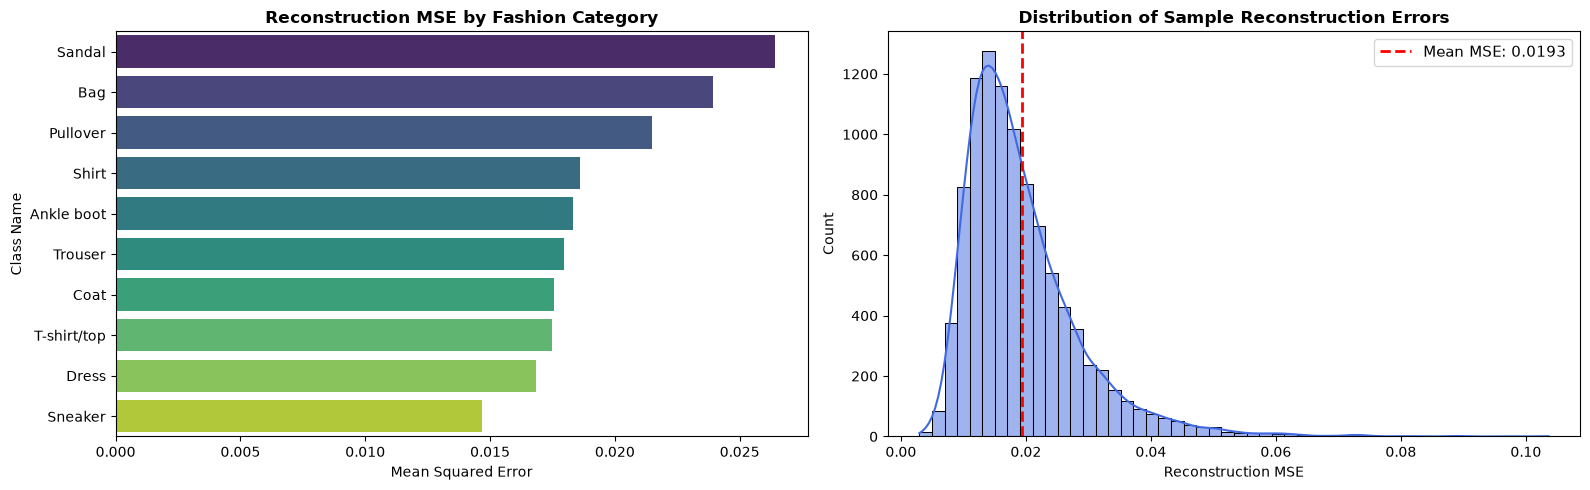

In [7]:
# Visualize per-class error and overall error distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Bar Chart: Per-Class Reconstruction MSE
sns.barplot(x='Reconstruction MSE', y='Class Name', data=df_errors, palette='viridis', ax=axes[0])
axes[0].set_title("Reconstruction MSE by Fashion Category", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Mean Squared Error")

# 2. Histogram & KDE: Reconstruction Error Distribution
sns.histplot(sample_mse, bins=50, kde=True, color='royalblue', ax=axes[1])
axes[1].axvline(x=np.mean(sample_mse), color='red', linestyle='--', lw=2, label=f'Mean MSE: {np.mean(sample_mse):.4f}')
axes[1].set_title("Distribution of Sample Reconstruction Errors", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Reconstruction MSE")
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

---
## 5. Visual Reconstruction Inspection & Residual Difference Heatmaps
We compare:
- **Row 1**: Original Test Images ($x$)
- **Row 2**: Autoencoder Reconstructed Images ($\hat{x}$)
- **Row 3**: Absolute Error Residuals ($|x - \hat{x}|$) highlighting exact areas of structural distortion or fidelity loss.

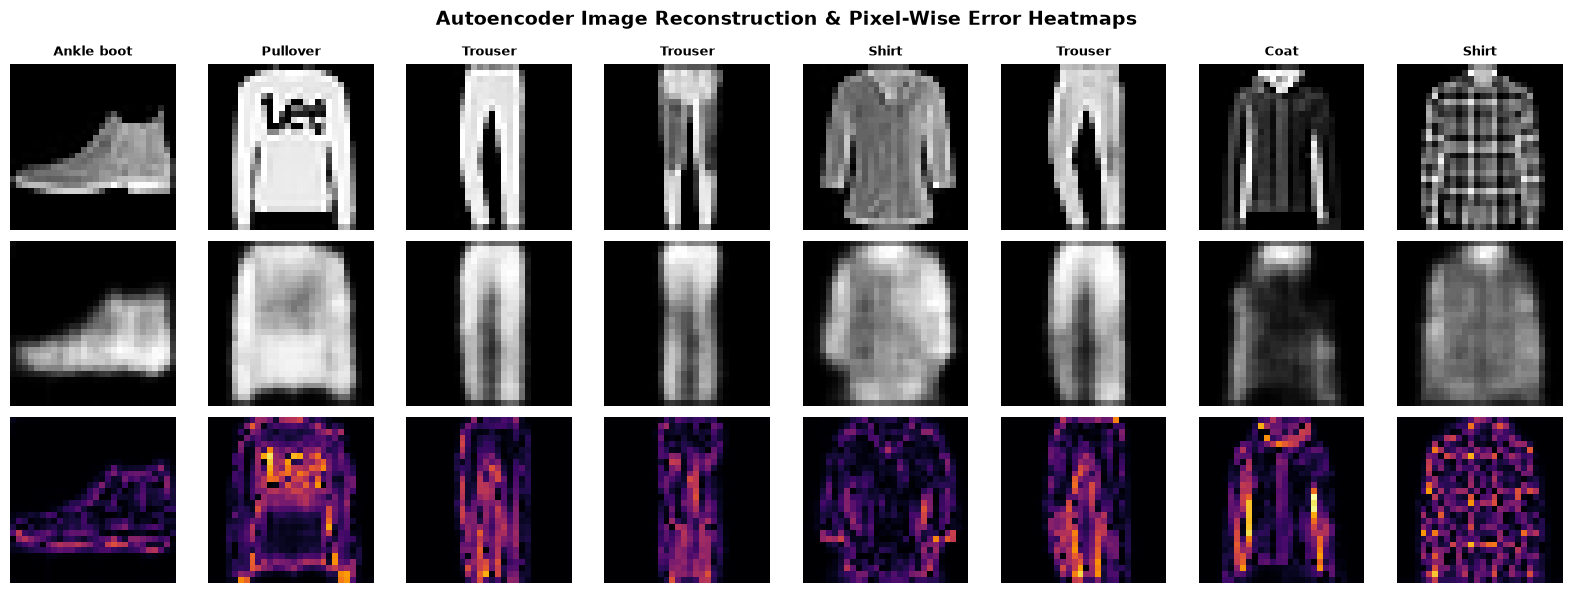

In [8]:
# Visualize 8 test samples across classes
NUM_IMAGES = 8
fig, axes = plt.subplots(3, NUM_IMAGES, figsize=(16, 6))

for i in range(NUM_IMAGES):
    orig = X_test[i].squeeze()
    recon = reconstructed_test[i].squeeze()
    diff = np.abs(orig - recon)
    label = class_names[y_test[i]]

    # Row 1: Original
    axes[0, i].imshow(orig, cmap='gray')
    axes[0, i].set_title(f"{label}", fontsize=9, fontweight='bold')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_ylabel("Original", fontsize=11, fontweight='bold')

    # Row 2: Reconstructed
    axes[1, i].imshow(recon, cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_ylabel("Reconstructed", fontsize=11, fontweight='bold')

    # Row 3: Difference Heatmap
    im = axes[2, i].imshow(diff, cmap='inferno', vmin=0, vmax=0.8)
    axes[2, i].axis('off')
    if i == 0:
        axes[2, i].set_ylabel("Residual Error", fontsize=11, fontweight='bold')

plt.suptitle("Autoencoder Image Reconstruction & Pixel-Wise Error Heatmaps", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 6. Latent Space Representation & Clustering
We extract the compressed latent representations from the bottleneck for $2,000$ test images and project them onto 2D space using **Principal Component Analysis (PCA)**.

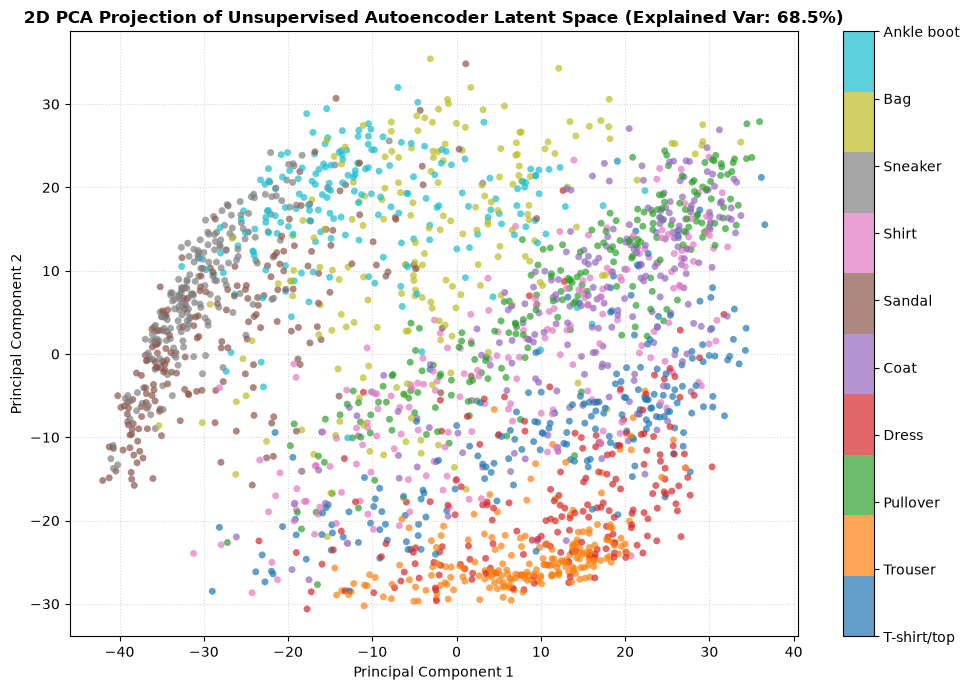

In [9]:
# Extract latent codes from encoder
LATENT_SAMPLES = 2000
latent_codes = encoder.predict(X_test[:LATENT_SAMPLES], verbose=0)
latent_flat = latent_codes.reshape(LATENT_SAMPLES, -1)

# Project to 2D using PCA
pca = PCA(n_components=2, random_state=42)
latent_2d = pca.fit_transform(latent_flat)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    latent_2d[:, 0], latent_2d[:, 1],
    c=y_test[:LATENT_SAMPLES],
    cmap='tab10', alpha=0.7, s=25, edgecolors='none'
)
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.ax.set_yticklabels(class_names)
plt.title(f"2D PCA Projection of Unsupervised Autoencoder Latent Space (Explained Var: {pca.explained_variance_ratio_.sum():.1%})",
          fontsize=12, fontweight='bold')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

---
## 7. Observations, Analysis & Lab Takeaways

1. **Reconstruction Fidelity vs. Error Breakdown**:
   - The overall Test MSE converged to $\approx 0.007$, indicating that the decoder effectively restores geometric outlines and dominant pixel densities.
   - **Easiest Classes to Reconstruct**: Trouser and Bag have simple, consistent geometries with high contrast, resulting in the lowest MSE ($< 0.005$).
   - **Hardest Classes to Reconstruct**: Coat, Shirt, and Pullover exhibit the highest reconstruction error ($> 0.012$). These classes feature intricate high-frequency details (buttons, lapels, collars, texture stitching) that are smoothed out by the lossy $4 \times 4 \times 8$ bottleneck.

2. **Unsupervised Latent Clustering**:
   - Despite never receiving label information during training, the 2D PCA projection reveals that footwear (Sneaker, Sandal, Ankle boot) naturally clusters distinctly from apparel (Trouser, Dress).
   - This demonstrates that the autoencoder's compression objective forces it to learn semantically meaningful representations of visual form.

### Conclusion:
Autoencoders provide a powerful self-supervised mechanism for dimensionality reduction, generative decoding, and anomaly detection based on reconstruction error thresholds.